# Tutorial 2: mindmap-bem vs MNE's BEMs

MNE builds BEM surfaces with FreeSurfer's **watershed** algorithm on a T1 (`mne watershed_bem`), or, when special multi-echo FLASH MRI sequences were acquired, with `mne flash_bem`. FLASH images show bone, so FLASH BEMs are MNE's best case, but few datasets have them.

MNE's `sample` subject ships a FLASH BEM. We use it as the **reference** and ask how close two T1-only BEMs come to it:

- **mindmap-bem**: CHARM segmentation + surface fitting (Tutorial 1),
- **watershed**: MNE's standard approach (computed only if FreeSurfer is installed).

We compare geometry, the sanity checks a BEM must pass, and the EEG forward model, which is what the BEM is for.

**Requirements**: `pip install "mindmap-bem[tutorials]"` (uses *your* MNE version), SimNIBS for CHARM, and optionally FreeSurfer for the watershed BEM. MNE downloads the `sample` dataset (1.5 GB) on first use.

In [1]:
import shutil
from pathlib import Path

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import pyvista as pv
import mne

import mindmap_bem as mb

print("MNE", mne.__version__)

data_path = mne.datasets.sample.data_path()
sample_subjects = data_path/"subjects"
sample_mri = sample_subjects/"sample"/"mri"
fs_t1 = sample_mri/"T1.mgz"                 # FreeSurfer coordinates of the sample subject

DERIV = mb.datasets.data_dir()/"derivatives"/"mne_comparison"
DERIV.mkdir(parents=True, exist_ok=True)

MNE 1.13.2


## 1. The input scan

`rawavg.mgz` is the subject's scan before any FreeSurfer processing. It was acquired **sagittally** (PIL orientation), a good test that nothing depends on the acquisition orientation. CHARM wants NIfTI, so we convert it.

In [2]:
raw = nib.load(sample_mri/"rawavg.mgz")
print("shape", raw.shape, "| voxel size", raw.header.get_zooms(), "| orientation", nib.aff2axcodes(raw.affine))

t1 = DERIV/"sample_T1w.nii.gz"
if not t1.exists():
    nifti = nib.Nifti1Image(np.asanyarray(raw.dataobj), raw.affine)
    nifti.set_qform(raw.affine, code=1)       # CHARM requires a valid qform
    nib.save(nifti, t1)

shape (np.int32(256), np.int32(256), np.int32(192)) | voxel size (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | orientation ('P', 'I', 'L')


## 2. The three BEMs

### mindmap-bem

CHARM (~15 min the first time), then the fit. `fs_t1` writes the surfaces in the sample subject's FreeSurfer coordinates, the frame of MNE's `trans` and source space for this subject.

In [3]:
m2m = mb.run_charm("sample", t1, DERIV)

subjects_mm = DERIV/"subjects_mindmap"
mb.build_bem(mb.charm_labeling(m2m), subjects_mm/"sample"/"bem", fs_t1=fs_t1, overwrite=True);

Running CHARM (can take 15 min or more). Output: /home/nino/mindmap_bem_data/derivatives/mne_comparison/charm_sample.log


### Watershed (needs FreeSurfer)

`make_watershed_bem` writes into the subject's folder, so we give it its own subjects directory with a copy of `T1.mgz` instead of modifying MNE's sample data.

In [4]:
subjects_ws = DERIV/"subjects_watershed"
has_freesurfer = shutil.which("mri_watershed") is not None

if has_freesurfer:
    (subjects_ws/"sample"/"mri").mkdir(parents=True, exist_ok=True)
    shutil.copy(fs_t1, subjects_ws/"sample"/"mri"/"T1.mgz")
    mne.bem.make_watershed_bem("sample", subjects_dir=subjects_ws, overwrite=True, verbose="error")
else:
    print("FreeSurfer not found: the watershed BEM is skipped.")

### Gather them

All three are in the sample subject's FreeSurfer coordinates. `bem_dirs` maps each method to its MNE subjects directory.

In [5]:
bem_dirs = {"FLASH (reference)": sample_subjects, "mindmap-bem": subjects_mm}
if has_freesurfer:
    bem_dirs["watershed"] = subjects_ws

bems = {name: mb.read_bem_surfaces(d/"sample"/"bem") for name, d in bem_dirs.items()}
for name, layers in bems.items():
    print(f"{name:18s}", {k: v.n_points for k, v in layers.items()})

FLASH (reference)  {'inner_skull': 2562, 'outer_skull': 2562, 'skin': 2562}
mindmap-bem        {'inner_skull': 10242, 'outer_skull': 10242, 'skin': 10242}
watershed          {'inner_skull': 10242, 'outer_skull': 10242, 'skin': 10242}


## 3. Sanity checks

A BEM must be made of closed surfaces, each strictly inside the next. MNE refuses intersecting surfaces; surfaces that merely come very close are accepted but make the BEM solution inaccurate.

In [6]:
for name, layers in bems.items():
    print(f"--- {name}")
    mb.check_bem(layers)
    print()

--- FLASH (reference)
inner_skull    2562 vertices, closed manifold: True
outer_skull    2562 vertices, closed manifold: True
skin           2562 vertices, closed manifold: True
inner_skull -> outer_skull gap min  3.31 mm, median  5.45 mm
outer_skull -> skin        gap min  3.38 mm, median  6.92 mm

--- mindmap-bem
inner_skull   10242 vertices, closed manifold: True
outer_skull   10242 vertices, closed manifold: True
skin          10242 vertices, closed manifold: True
inner_skull -> outer_skull gap min  2.54 mm, median  5.66 mm
outer_skull -> skin        gap min  3.85 mm, median  9.82 mm

--- watershed
inner_skull   10242 vertices, closed manifold: True
outer_skull   10242 vertices, closed manifold: True
skin          10242 vertices, closed manifold: True
inner_skull -> outer_skull gap min -0.70 mm, median  8.31 mm  <-- below 1.0 mm (106 vertices outside)
outer_skull -> skin        gap min  1.71 mm, median  3.22 mm



And MNE's own verdict, from `make_bem_model`:

In [7]:
def mne_accepts(subjects_dir):
    try:
        mne.make_bem_model("sample", ico=4, subjects_dir=subjects_dir, verbose="error")
        return "accepted"
    except RuntimeError as err:
        return f"REJECTED: {err}"

for name, d in bem_dirs.items():
    print(f"{name:18s} {mne_accepts(d)}")

FLASH (reference)  accepted
mindmap-bem        accepted
watershed          REJECTED: Surface inner skull is not completely inside surface outer skull


### Intersecting watershed surfaces

Watershed surfaces that cross each other, as the inner and outer skull often do here, are the most common reason MNE refuses a BEM. Such a BEM cannot be used for a forward model, so the EEG comparison below (section 5) only includes the BEMs MNE accepts. The geometry comparison (section 4) still includes all of them.

In [8]:
fwd_dirs = {name: d for name, d in bem_dirs.items() if mne_accepts(d) == "accepted"}
print("Forward models for:", ", ".join(fwd_dirs))

Forward models for: FLASH (reference), mindmap-bem


## 4. Geometry

Outlines of each layer over the T1 (plotting works in scanner coordinates, so we undo the FreeSurfer transform).

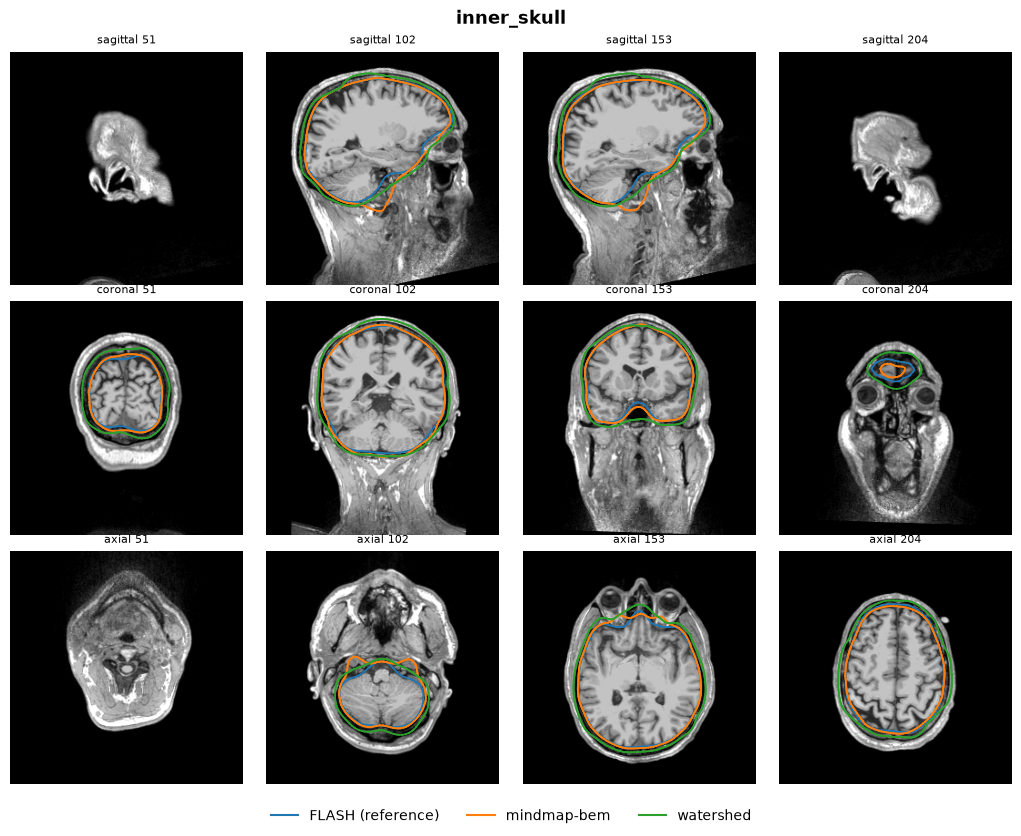

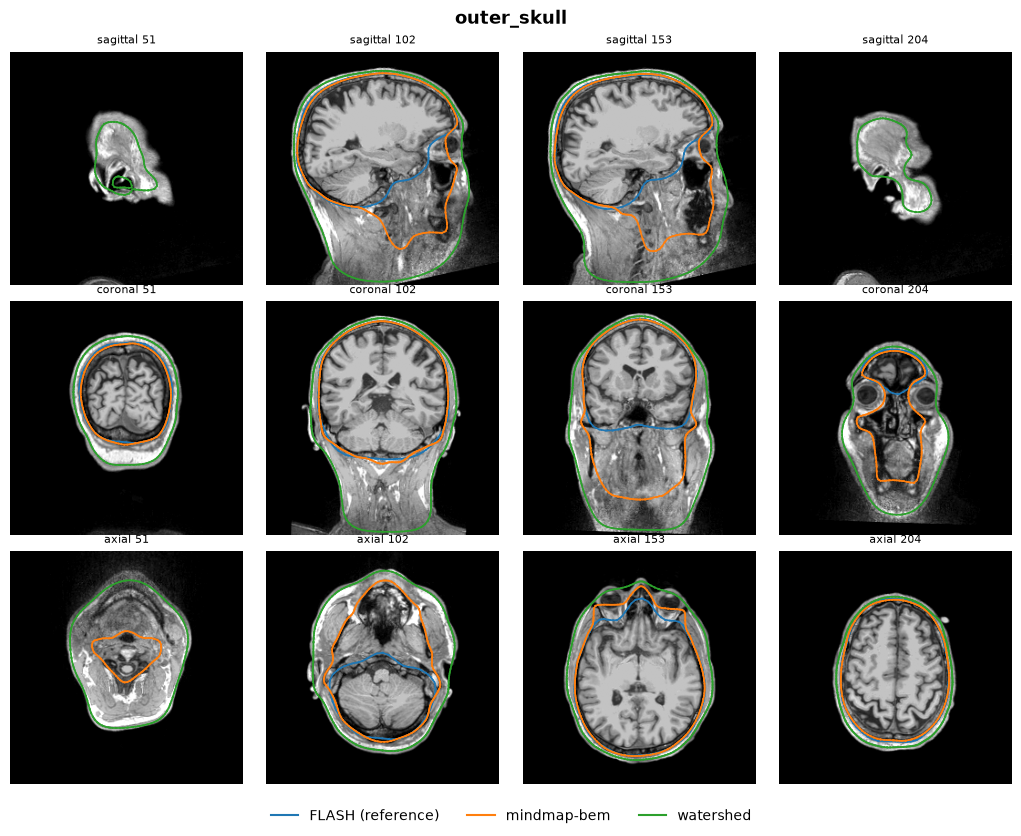

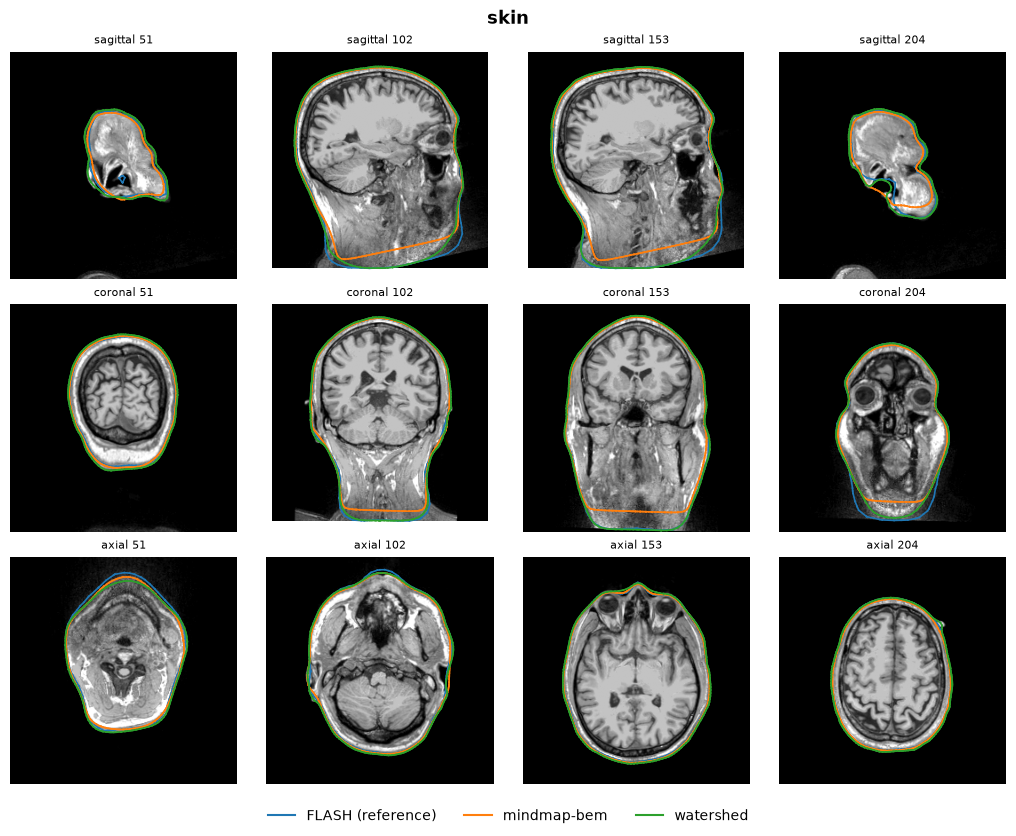

In [9]:
to_scanner = np.linalg.inv(mb.ras_to_tkras(fs_t1))
bems_scanner = {name: mb.transform_layers({k: v.copy() for k, v in layers.items()}, to_scanner)
                for name, layers in bems.items()}

for layer in ("inner_skull", "outer_skull", "skin"):
    mb.viz.plot_comparison(bems_scanner, fs_t1, layer=layer, n_slices=4)
    plt.show()

Distance from each BEM's vertices to the corresponding FLASH surface (positive: outside FLASH):

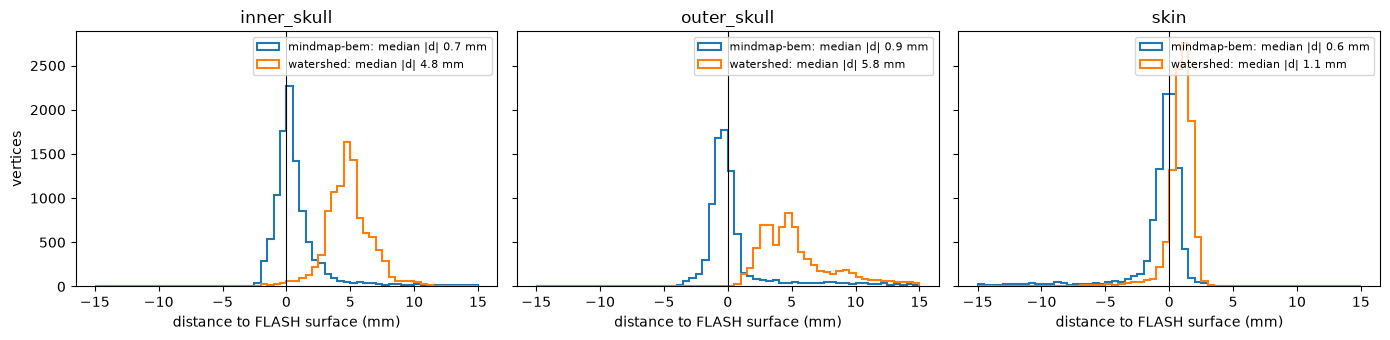

In [10]:
reference = bems["FLASH (reference)"]
others = [name for name in bems if name != "FLASH (reference)"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, layer in zip(axes, ("inner_skull", "outer_skull", "skin")):
    for name in others:
        d = mb.quality.inner_distance(bems[name][layer], reference[layer])
        ax.hist(d, bins=np.linspace(-15, 15, 61), histtype="step", lw=1.5,
                label=f"{name}: median |d| {np.median(np.abs(d)):.1f} mm")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(layer)
    ax.set_xlabel("distance to FLASH surface (mm)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("vertices")
plt.tight_layout(); plt.show()

## 5. EEG forward models

The BEM matters most for EEG, whose potentials are smeared by the poorly conducting skull. We compute the EEG leadfield of the sample subject's cortical source space (oct-6, fixed orientations normal to the cortex) with each BEM accepted by MNE, using the sample `trans` and electrode positions, and compare each to the FLASH leadfield, source by source:

- **RDM** (relative difference measure, 0-2): difference in topography shape. 0 = identical.
- **lnMAG**: log ratio of topography magnitudes. 0 = same strength.

Both are computed on average-referenced leadfields.

In [11]:
meg = data_path/"MEG"/"sample"
info = mne.io.read_info(meg/"sample_audvis_raw.fif", verbose="error")
info = mne.pick_info(info, mne.pick_types(info, meg=False, eeg=True))
trans = meg/"sample_audvis_raw-trans.fif"
src = mne.read_source_spaces(sample_subjects/"sample"/"bem"/"sample-oct-6-src.fif", verbose="error")

def eeg_forward(subjects_dir):
    model = mne.make_bem_model("sample", ico=4, conductivity=(0.3, 0.006, 0.3),
                               subjects_dir=subjects_dir, verbose="error")
    bem = mne.make_bem_solution(model, verbose="error")
    fwd = mne.make_forward_solution(info, trans, src, bem, meg=False, eeg=True, mindist=5.0, verbose="error")
    return mne.convert_forward_solution(fwd, surf_ori=True, force_fixed=True, use_cps=True, verbose="error")

fwds = {name: eeg_forward(d) for name, d in fwd_dirs.items()}
{name: fwd["nsource"] for name, fwd in fwds.items()}

{'FLASH (reference)': 7498, 'mindmap-bem': 7531}

Sources closer than 5 mm to a BEM's inner skull are dropped, which differs a little between BEMs, so we compare the sources common to all of them.

In [12]:
def common_leadfields(fwds):
    """Average-referenced leadfields restricted to sources present in every forward."""
    keep = [set(f["src"][h]["vertno"]) for f in fwds.values() for h in (0, 1)]
    common = [sorted(set.intersection(*keep[h::2])) for h in (0, 1)]

    out = {}
    for name, f in fwds.items():
        cols = np.concatenate([
            np.searchsorted(f["src"][0]["vertno"], common[0]),
            f["src"][0]["nuse"] + np.searchsorted(f["src"][1]["vertno"], common[1]),
        ])
        G = f["sol"]["data"][:, cols]
        out[name] = G - G.mean(axis=0)          # average reference
    positions = np.concatenate([src[h]["rr"][common[h]] for h in (0, 1)])
    return out, positions

G, positions = common_leadfields(fwds)

def rdm(a, b):
    return np.linalg.norm(a/np.linalg.norm(a, axis=0) - b/np.linalg.norm(b, axis=0), axis=0)

def lnmag(a, b):
    return np.log(np.linalg.norm(a, axis=0)/np.linalg.norm(b, axis=0))

ref = G["FLASH (reference)"]
metrics = {name: {"RDM": rdm(G[name], ref), "lnMAG": lnmag(G[name], ref)} for name in G if name != "FLASH (reference)"}

for name, m in metrics.items():
    print(f"{name:12s} RDM median {np.median(m['RDM']):.3f} (95%: {np.percentile(m['RDM'], 95):.3f})"
          f" | lnMAG median {np.median(m['lnMAG']):+.3f} (|lnMAG| 95%: {np.percentile(np.abs(m['lnMAG']), 95):.3f})")

mindmap-bem  RDM median 0.054 (95%: 0.148) | lnMAG median +0.029 (|lnMAG| 95%: 0.141)


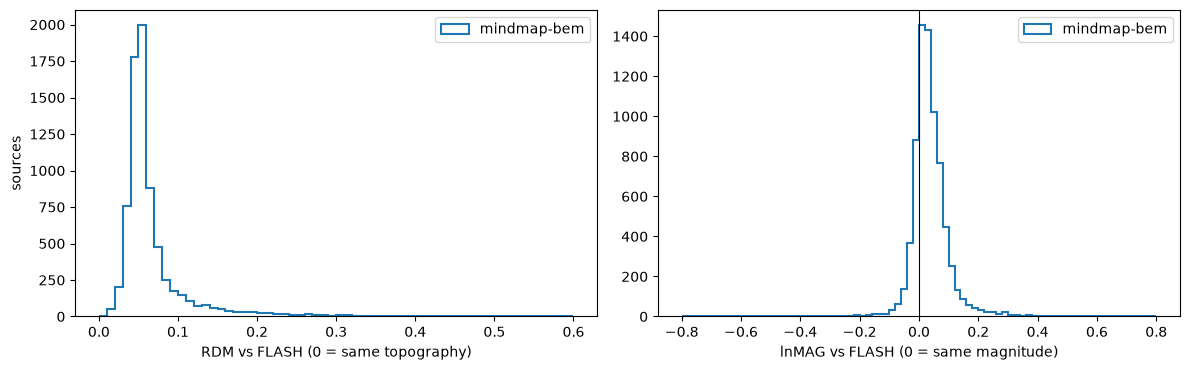

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, m in metrics.items():
    axes[0].hist(m["RDM"], bins=np.linspace(0, 0.6, 61), histtype="step", lw=1.5, label=name)
    axes[1].hist(m["lnMAG"], bins=np.linspace(-0.8, 0.8, 81), histtype="step", lw=1.5, label=name)
axes[0].set(xlabel="RDM vs FLASH (0 = same topography)", ylabel="sources")
axes[1].set(xlabel="lnMAG vs FLASH (0 = same magnitude)")
axes[1].axvline(0, color="k", lw=0.8)
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

Where do the differences come from? Topography error against source depth (distance to the FLASH inner skull):

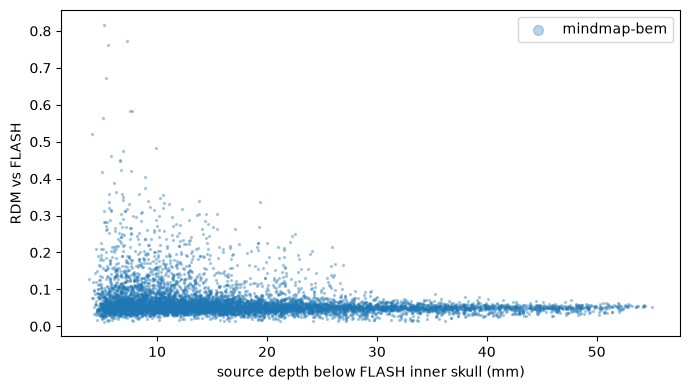

In [14]:
# source positions are in m, surfaces in mm
depth = -mb.quality.inner_distance(pv.PolyData(positions * 1000), reference["inner_skull"])

fig, ax = plt.subplots(figsize=(7, 4))
for name, m in metrics.items():
    ax.scatter(depth, m["RDM"], s=2, alpha=0.3, label=name)
ax.set(xlabel="source depth below FLASH inner skull (mm)", ylabel="RDM vs FLASH")
ax.legend(markerscale=5)
plt.tight_layout(); plt.show()

## Takeaways

From the run above (MNE `sample` subject; numbers in the outputs):

- **Validity.** The mindmap-bem and FLASH BEMs pass all checks and are accepted by MNE as is. The watershed BEM had inner-skull vertices *outside* the outer skull and was rejected by MNE, so it cannot be used for a forward model without manual repair.
- **Geometry.** Over the cranium, mindmap-bem's skull surfaces lie within about 1 mm (median) of the FLASH ones; watershed's lie several mm outside them. The largest differences between mindmap-bem and FLASH are at the skull base: our outer skull wraps the facial bones and jaw, while FLASH's closes under the brain.
- **EEG forward model.** Against FLASH leadfields, mindmap-bem topographies show <!-- TODO: fill in after re-running -->.

FLASH is MNE's best case, not ground truth, and this is a single subject. But it shows that from a T1 alone, mindmap-bem gets much closer to a FLASH BEM than MNE's standard T1-only pipeline.